In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


# Qiskit Superposition 05
Various state can be expressed at the same time by creating superposition.
In terms of n bits binary number, we can easily make n states by operating Hadamard to all the qubits.  

Now what if we want to make 2^n+1 superposition states on n qubits?

In [2]:
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit_backend_config import IBMQ, execute, Aer
from qiskit.visualization import plot_histogram
import math

In [3]:
def ry_arc(qubit, num):
    theta = 2 * np.arccos(1 / np.sqrt(num))
    qc.ry(theta, q[qubit])

{'1011': 115, '1111': 116, '0111': 84, '0101': 135, '0011': 127, '0001': 103, '1101': 111, '0000': 120, '1001': 113}


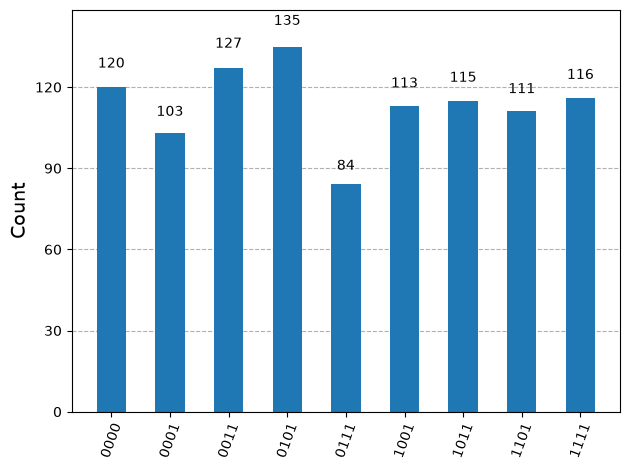

In [4]:
#0000, 0001, 0011, 0101, 0111, 1001, 1011, 1101, 1111
q = QuantumRegister(4, 'q')
c = ClassicalRegister(4, 'c')
qc = QuantumCircuit(q, c)

ry_arc(0, 9)
qc.ch(q[0], q[1])
qc.ch(q[0], q[2])
qc.ch(q[0], q[3])


qc.measure(q, c)

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

### 2^n + 1 superposition states on n qubits
If we want to make 2^n + 1 states (e.g 33 states for 5-qubit circuit), we can easily make that superposition.
There are 2 steps:
    1) Make the probability amplitude of first qubit's |0> 1/√(2^n + 1) by operating ry gates
    2) Operate ch gate for n times. Control qubit must be a first qubit.
    
In this way, we can make 5, 9, 17, 33, ...superpositon states for 2-qubit, 3-qubit, 4-qubit, 5-qubit and so on...

In [5]:
# generalize
def two_pwr_plus_1(quNum):
    ry_arc(0, 1 + 2 ** (quNum - 1)) # step 1
    for i in range(quNum - 1):
        qc.ch(q[0], q[i + 1])

{'10111': 58, '01011': 58, '10011': 58, '11101': 62, '00101': 61, '01001': 57, '00011': 60, '01101': 77, '11111': 52, '11011': 69, '11001': 61, '00000': 61, '10101': 59, '00001': 57, '00111': 48, '10001': 72, '01111': 54}


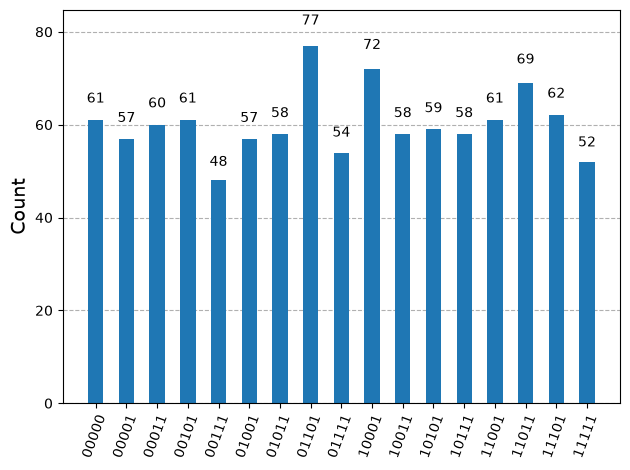

In [6]:
#test - 33 states on 5 qubits
quNum = 5
q = QuantumRegister(quNum, 'q')
c = ClassicalRegister(quNum, 'c')
qc = QuantumCircuit(q, c)

two_pwr_plus_1(quNum)

qc.measure(q, c)

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

Calculate Avg Count of a particular state for a circuit

In [ ]:
#Calculating avg count of state 00101 on 5 qubit circuit
mem = 0
for i in range(100):
    quNum = 5
    q = QuantumRegister(quNum, 'q')
    c = ClassicalRegister(quNum, 'c')
    qc = QuantumCircuit(q, c)

    two_pwr_plus_1(quNum)

    qc.measure(q, c)

    r = execute(qc, Aer.get_backend('qasm_simulator')).result()
    rc = r.get_counts()
    #sum up the count of the required state in memory
    mem += rc['00101']
print('Average count is ' + str(mem / 100))
print('Ideal percentage is ' + str(100 / 17) + '% | In this run, ' + str(mem/1024) + '%')

Average count is59.05
Ideal percentage is 5.882352941176471% | In this run, 5.7666015625%
